# High-column-density absorbers in Lyman-alpha forest

In this tutorial, we will go through the scientific motivation behind `hcd_priya` and how to use the package.

Three main points:

1. **Why do we care about HCD?** We will first look at the Lyman-alpha forest and different populations of HCD absorbers along quasar sightlines: Lyman limit systems (LLSs), sub-damped Lyman-alpha absorbers (subDLAs), and damped Lyman-alpha absorbers (DLAs).

2. **What can we learn from this HCD emulator?** We will explore how the flux power spectrum and the abundance of different populations of absorbers depend on cosmology and astrophysics. We will also see how changing the abundance of these absorbers affects the total flux power spectrum.

3. **How do we incorporate HCD absorbers into cosmological inference?** We will use a mock data set to illustrate how to construct a Gaussian likelihood with the emulator, and examine the results of a previously run mock-recovery analysis.

**To run this tutorial:** Install the package with `pip install "hcd-priya[tutorials]"` (Python 3.11 or later), then open this notebook in Jupyter. The trained emulator comes with the package.

## Set-up

To run this tutorial, clone the repository and open this notebook from `notebooks/tutorial/`. You can install the package and the dependencies for this tutorial with:

`pip install "hcd-priya[tutorials]"`

The trained emulator comes with the package, so there is no need to train the model yourself.

In Part I and II, we will use some published measurements and simulation data available in `docs/figures/data/`. For the mock-recovery example in Part III, we will need to download and unpack the example data set in the same directory as this notebook:

```bash
curl -L -O https://github.com/jibanCat/hcd_priya/releases/download/v1.0.0/hcd_priya_example_download.tar.gz
tar -xzf hcd_priya_example_download.tar.gz
```

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

import hcd_analysis
import hcd_analysis.predictor as hp
from hcd_analysis import hcd_template, likelihood

# The clone of the repository: published measurements and the example script are read from it.
REPO = "../.."
print("hcd_analysis", hcd_analysis.__version__)

hcd_analysis 1.0.0


In [2]:
# One plotting style for every figure of this notebook.
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.constrained_layout.use": True,
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
        "lines.linewidth": 1.8,
    }
)

## Part I. Scientific motivation


[![The Lyman-alpha forest and its DLA](https://jibancat.github.io/images/play-dla-animation-2x.jpg)](https://www.youtube.com/watch?v=T091PUsAJuA)

**Fig. 1. The Lyman-alpha forest and a damped Lyman-alpha absorber (DLA) along a quasar sightline in the PRIYA simulation (Bird et al. 2023).** As the light from a distant quasar travels through the Universe, it is absorbed by neutral hydrogen along the sightline. When the sightline passes through a region with a high column density of neutral hydrogen, we can see broad damping wings in the spectrum.

Click on the image to watch the animation.

### Three classes of HCD absorbers

We divide HCD absorbers into three populations based on their neutral hydrogen column density $N_\mathrm{HI}$: LLSs, subDLAs, and DLAs.

To study their impact on the Lyman-alpha forest, we classify each sightline based on the absorber with the highest $N_\mathrm{HI}$ along that sightline. We refer to sightlines without any HCD absorbers as clean sightlines.

We therefore have four populations of sightlines: clean, LLS, subDLA, and DLA.

### Why Lyman-alpha forest and HCD absorbers are modelled separately?

- **In observations:** We often identify DLAs in individual quasar spectra and either mask the absorption or correct for their damping wings. LLSs, however, are much more difficult to identify in low-resolution spectra.

- **In simulations:** Most Lyman-alpha forest simulations focus on modeling the diffuse intergalactic medium (IGM) at high resolution, leaving the correction for HCD absorbers to the data or likelihood level. The PRIYA simulation suite takes a different approach by also simulating the population of high-column-density absorbers.

Since not all HCD absorbers can be identified and removed from the observed spectra, we need to account for their contribution to the measured one-dimensional flux power spectrum (P1D) when doing cosmological inference.

### Why is HCD contamination important ?

Different populations of HCD absorbers affect the P1D at different scales. While DLAs primarily affect large scales through their broad damping wings, LLSs and subDLAs can have a significant impact on smaller scales.

Two recent cosmological analyses highlight the importance of modeling these absorbers:

- [Ho et al. (2026)](https://arxiv.org/abs/2509.18271) found that LLS contamination is strongly degenerate with the amplitude of the primordial power spectrum in high-resolution P1D measurements. In particular, the selection of quasars in KODIAQ-SQUAD toward known absorbers leads to biased cosmological constraints. Modeling LLS contamination becomes particularly important when probing scales $k > 0.045$ s/km.
- [Chaves-Montero et al. (2026)](https://arxiv.org/abs/2601.21432) found that LLSs are the dominant population of residual HCD contamination across the scales probed by the DESI DR1 P1D measurements ([Karaçaylı et al. 2025](https://arxiv.org/abs/2505.07974); [Ravoux et al. 2025](https://arxiv.org/abs/2505.09493)).


## Part II. The HCD emulator

The HCD emulator is trained on the PRIYA suite of hydrodynamical simulations. Given a set of nine cosmological and astrophysical parameters, a redshift, and a mean flux, the emulator predicts:

- The flux power spectrum (P1D) of four populations of sightlines: clean, LLS, subDLA, and DLA.
- The fraction of sightlines belonging to each population.
- The incidence rate ($dN/dX$) of LLSs, subDLAs, and DLAs.
- The column density distribution function (CDDF).

Let's first load the trained emulator and explore it.

In [3]:
# the trained LF+MF model, from the installed package hcd-priya-models
emu = hp.load_published()
print("model release:", emu.provenance["release"]["release_version"])

model release: 1.0.0


In [4]:
# The midpoint of the range each parameter was trained on. It is a point to try the model at:
# not a fiducial cosmology, not a best fit and not a simulation.
PARAMS = {
    "ns": 0.925,  # slope of the primordial power spectrum at k = 0.78 / Mpc
    "Ap": 1.9e-9,  # its amplitude at the same wavenumber
    "herei": 4.0,  # redshift at which helium reionization starts
    "heref": 2.7,  # redshift at which helium reionization ends
    "alphaq": 2.15,  # quasar spectral index, which sets the heating of helium reionization
    "hub": 0.70,  # dimensionless Hubble parameter h
    "omegamh2": 0.143,  # Omega_m h^2
    "hireionz": 7.25,  # redshift of hydrogen reionization
    "bhfeedback": 0.05,  # black-hole feedback strength
}
for name, (low, high) in zip(hp.PARAM_NAMES, hp.PARAM_LIMITS):
    print(f"{name:11s} trained from {low:.4g} to {high:.4g}; used here {PARAMS[name]:.4g}")

ns          trained from 0.8 to 1.05; used here 0.925
Ap          trained from 1.2e-09 to 2.6e-09; used here 1.9e-09
herei       trained from 3.5 to 4.5; used here 4
heref       trained from 2.2 to 3.2; used here 2.7
alphaq      trained from 1.3 to 3; used here 2.15
hub         trained from 0.65 to 0.75; used here 0.7
omegamh2    trained from 0.14 to 0.146; used here 0.143
hireionz    trained from 6.5 to 8; used here 7.25
bhfeedback  trained from 0.03 to 0.07; used here 0.05


**Fig. 4.** Overview of the HCD emulator. Given nine cosmological and astrophysical parameters, a redshift, and a mean flux, the emulator predicts the P1D of four populations of sightlines, the incidence $dN/dX$, and the column density distribution function (CDDF). We use a multi-fidelity approach to correct the P1D predictions for the resolution of the simulations.

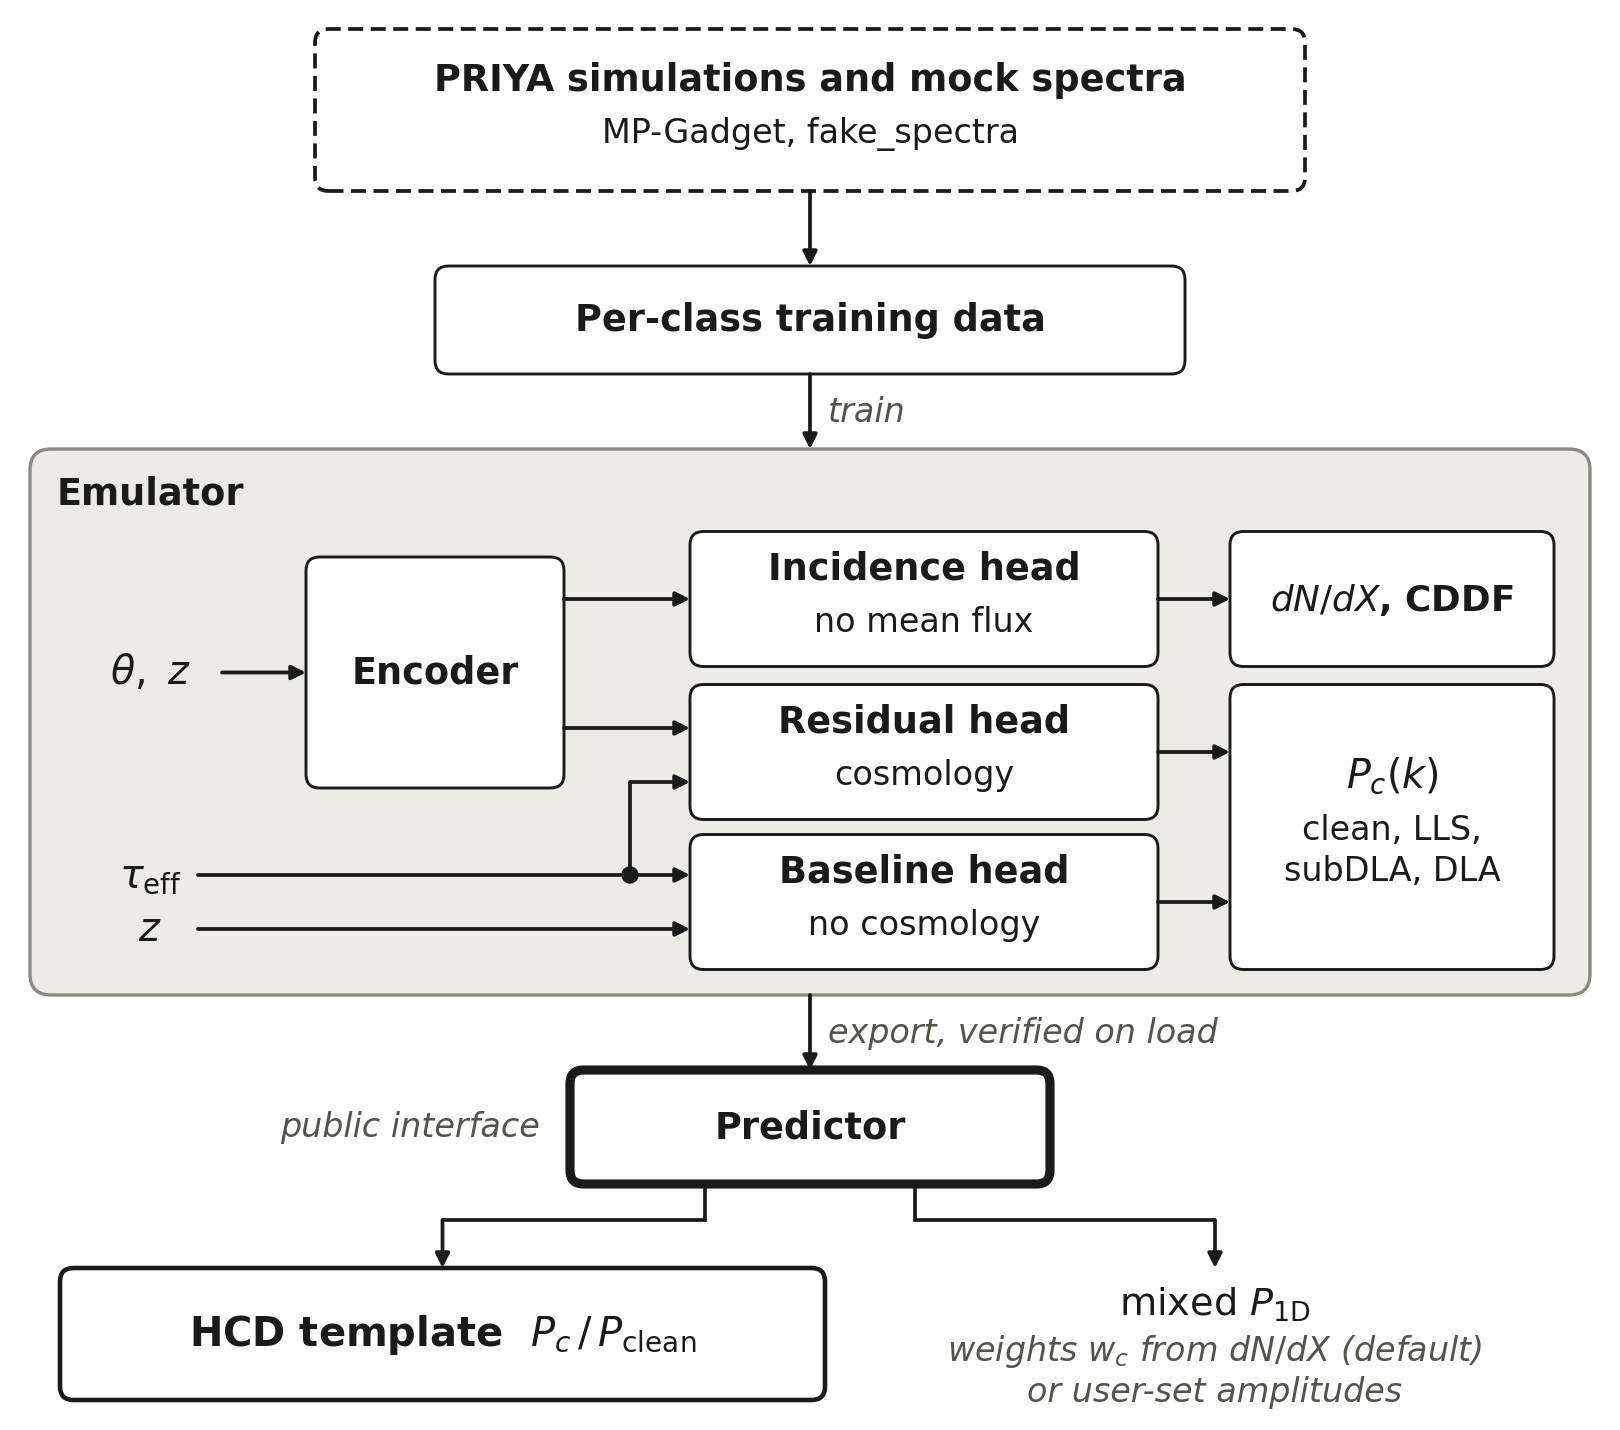

In [5]:
display(Image(filename="assets/figures/joss_architecture.png", width=900))

In [6]:
# z is a PRIYA snapshot redshift; tau0_amp = 1 and dtau0 = 0 give the mean flux
# of Kim et al. (2007).
pred = emu.predict(PARAMS, z=3.0, tau0_amp=1.0, dtau0=0.0)

print("classes, in the order of P_class:", hp.CLASSES)
print(f"pred.k: shape {pred.k.shape}, from {pred.k[0]:.2e} to {pred.k[-1]:.2e} s/km")
print(f"pred.P_class: shape {pred.P_class.shape}, in km/s")
print("pred.w_c, the sightline fractions of", hp.HCD_CLASSES, ":", np.round(pred.w_c, 4))
print("pred.dndx, the incidence dN/dX of the same classes:", np.round(pred.dndx, 4))
print("flags that are set:", sorted(name for name, value in pred.flags.items() if value is True))

classes, in the order of P_class: ('clean', 'LLS', 'subDLA', 'DLA')
pred.k: shape (172,), from 4.76e-04 to 8.18e-02 s/km
pred.P_class: shape (4, 172), in km/s
pred.w_c, the sightline fractions of ('LLS', 'subDLA', 'DLA') : [0.2126 0.0786 0.0376]
pred.dndx, the incidence dN/dX of the same classes: [0.4337 0.1343 0.0602]
flags that are set: ['incidence_heldout_error_available', 'incidence_mf_applied', 'k_downweighted', 'mf_applied', 'p1d_validation_available']


### Conventions for the flux power spectrum

Before looking at the P1D of different populations of sightlines, let's go through a few conventions:

- We define the flux fluctuation as $\delta_F = F / \langle F \rangle - 1$, where $\langle F \rangle$ is the mean flux of all sightlines, regardless of their HCD population.
- We use the angular wavenumber $k$ in units of s/km.
- We apply the same filtering as in the PRIYA Lyman-alpha forest emulator, where the cores of strong absorbers are masked. The P1D predicted by our emulator does not include the absorption removed by this filter.


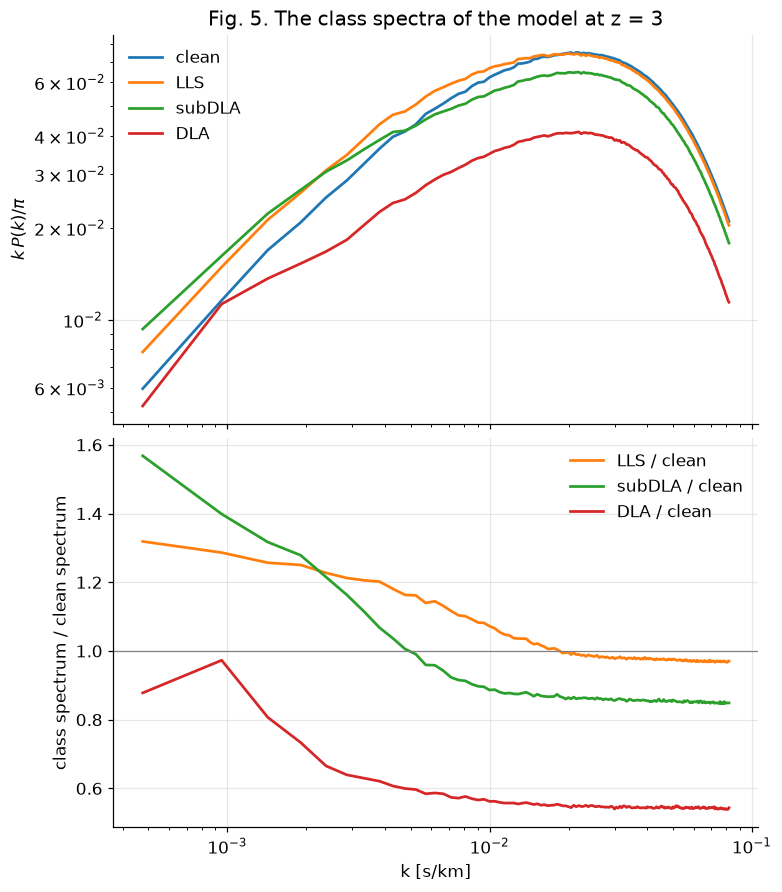

In [7]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 8), sharex=True)
for i, name in enumerate(hp.CLASSES):
    top.loglog(pred.k, pred.k * pred.P_class[i] / np.pi, color=f"C{i}", label=name)
    # each HCD class over the clean forest: the ratio that a template of HCD absorbers models
    if name != "clean":
        ratio = pred.P_class[i] / pred.P_class[0]
        bottom.semilogx(pred.k, ratio, color=f"C{i}", label=f"{name} / clean")
bottom.axhline(1.0, color="grey", lw=0.8)
top.set_ylabel(r"$k\,P(k)/\pi$")
bottom.set_ylabel("class spectrum / clean spectrum")
bottom.set_xlabel("k [s/km]")
top.set_title("Fig. 5. The class spectra of the model at z = 3")
top.legend()
bottom.legend()
plt.show()

There are two things to keep in mind when interpreting the ratio of the P1D of each HCD population to that of clean sightlines. First, we use the same mean flux to normalize all four populations of sightlines. Second, we have already masked the cores of strong absorbers following the PRIYA filtering procedure.

### Combining different populations of sightlines

Now that we have the P1D of each population of sightlines, how do we combine them to predict the total P1D?

We can write the total P1D as a weighted sum of the four populations:

$$
P_\mathrm{mix}(k) = P_\mathrm{clean}(k) + \sum_c A_c\,[P_c(k) - P_\mathrm{clean}(k)],
\qquad c \in \{\mathrm{LLS}, \mathrm{subDLA}, \mathrm{DLA}\}.
$$

Here, $A_c$ is the fraction of sightlines belonging to each HCD population. The emulator predicts these fractions from the PRIYA simulations (`pred.w_c`), but we can also treat them as free parameters when modeling HCD contamination.

We can use `hp.add_hcd(pred, A)` to compute the total P1D for a given set of fractions. Note that the combined P1D still follows the PRIYA filtering convention discussed above.

Let's explore how the total P1D changes when we vary the fraction of each HCD population while keeping the cosmological and astrophysical parameters fixed.

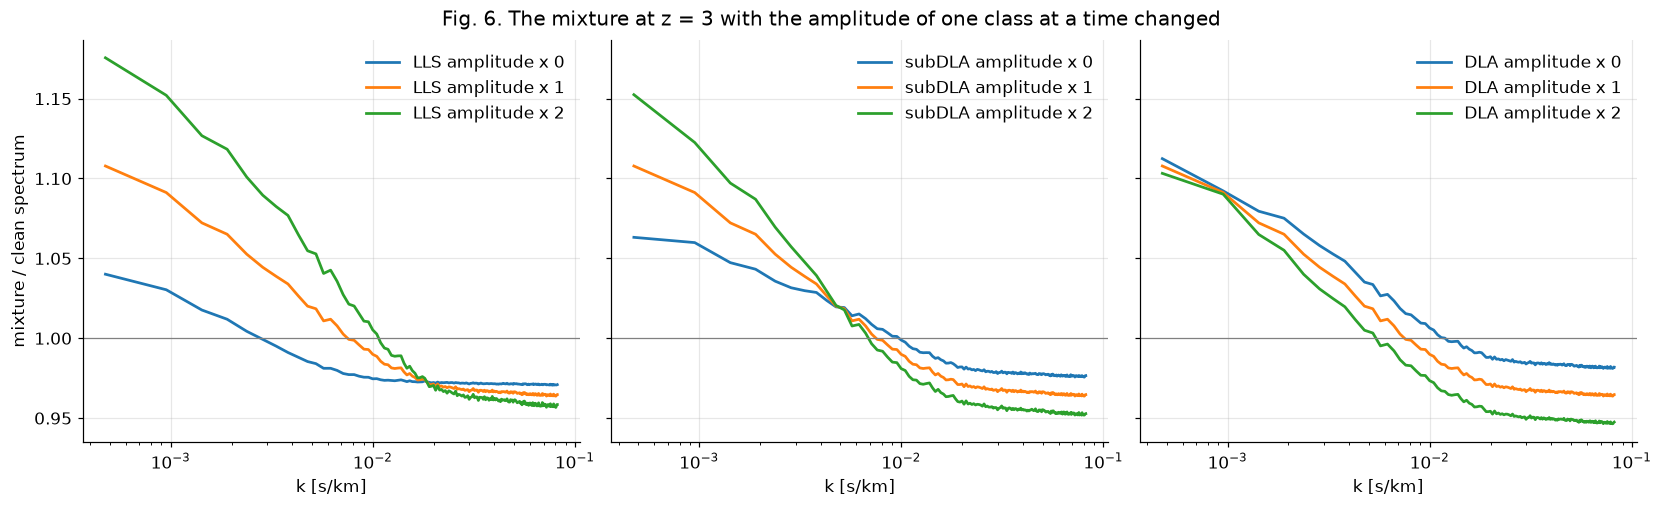

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for c, (ax, name) in enumerate(zip(axes, hp.HCD_CLASSES)):
    for factor in (0.0, 1.0, 2.0):
        # one class at a time; the other two stay at the model's own fractions
        amplitudes = pred.w_c.copy()
        amplitudes[c] *= factor
        mixture = hp.add_hcd(pred, amplitudes)
        ax.semilogx(pred.k, mixture / pred.P_class[0], label=f"{name} amplitude x {factor:g}")
    ax.axhline(1.0, color="grey", lw=0.8)
    ax.set_xlabel("k [s/km]")
    ax.legend()
axes[0].set_ylabel("mixture / clean spectrum")
fig.suptitle("Fig. 6. The mixture at z = 3 with the amplitude of one class at a time changed")
plt.show()

### The incidence of HCD absorbers

So far, we have looked at how different populations of HCD absorbers affect the P1D. We now turn to the abundance of these absorbers.

The emulator predicts the incidence $dN/dX$ (the number of absorbers per unit absorption distance) for LLSs, subDLAs, and DLAs (`pred.dndx`), as well as the column density distribution function (CDDF).

We also provide an estimate of the prediction error from held-out simulations (`pred.dndx_lower` and `pred.dndx_upper`).

Let's first look at how the predicted abundance of HCD absorbers evolves with redshift and compare it with observations.

In [9]:
for c, name in enumerate(hp.HCD_CLASSES):
    value, low, high = pred.dndx[c], pred.dndx_lower[c], pred.dndx_upper[c]
    print(f"dN/dX of {name} at z = 3: {value:.4f}, held-out range {low:.4f} to {high:.4f}")

dN/dX of LLS at z = 3: 0.4337, held-out range 0.4242 to 0.4435
dN/dX of subDLA at z = 3: 0.1343, held-out range 0.1314 to 0.1372
dN/dX of DLA at z = 3: 0.0602, held-out range 0.0595 to 0.0609


In [10]:
# One prediction per snapshot from z = 2.2 to 4.6, the redshifts of the multi-fidelity model.
redshifts = [float(z) for z in hp.Z_GRID if 2.2 <= z <= 4.6]
preds = [emu.predict(PARAMS, z=z, tau0_amp=1.0, dtau0=0.0) for z in redshifts]
dndx = np.array([p.dndx for p in preds])
dndx_lower = np.array([p.dndx_lower for p in preds])
dndx_upper = np.array([p.dndx_upper for p in preds])
print("dN/dX has one row per redshift and one column per class:", dndx.shape, hp.HCD_CLASSES)

# dN/dX and f(N_HI) are per unit absorption distance X, which depends on the matter density.
OMEGA_M_MODEL = PARAMS["omegamh2"] / PARAMS["hub"] ** 2
OMEGA_M_HO21 = 0.279  # the cosmology of X in Ho, Bird and Garnett (2021)
print(f"Omega_m of the model at PARAMS: {OMEGA_M_MODEL:.4f}")

dN/dX has one row per redshift and one column per class: (13, 3) ('LLS', 'subDLA', 'DLA')
Omega_m of the model at PARAMS: 0.2918


In [11]:
def dx_dz(z: np.ndarray, omega_m: float) -> np.ndarray:
    """Absorption distance per unit redshift, dX/dz = (1 + z)^2 / E(z), in a flat cosmology.

    dN/dX and f(N_HI) are counts per unit X, and X depends on the matter density. A measurement
    published in one cosmology is put on the model's X by the ratio of the two dX/dz.

    Parameters
    ----------
    z : numpy.ndarray
        Redshift.
    omega_m : float
        Matter density parameter of the flat cosmology.

    Returns
    -------
    numpy.ndarray
        dX/dz at each redshift.
    """
    return (1.0 + z) ** 2 / np.sqrt(omega_m * (1.0 + z) ** 3 + 1.0 - omega_m)

In [12]:
# All absorbers with N_HI >= 10^17.5 cm^-2 (optical depth 2 at the Lyman limit): what surveys of
# Lyman limit systems count. It is the sum of f(N_HI) times the bin width above that threshold.
log_nhi = preds[0].log_nhi
half_bin = (log_nhi[1] - log_nhi[0]) / 2.0
# the bin that holds 17.5 is counted from 17.5 to its upper edge; bins below it get zero width
widths = 10.0 ** (log_nhi + half_bin) - 10.0 ** np.maximum(log_nhi - half_bin, 17.5)
widths = np.clip(widths, 0.0, None)
cddf = np.array([p.cddf for p in preds])
dndx_all = np.nansum(cddf * widths, axis=1)  # a bin without support (NaN) is left out
print("dN/dX of all absorbers above 10^17.5, one value per redshift:", np.round(dndx_all, 3))

dN/dX of all absorbers above 10^17.5, one value per redshift: [0.398 0.43  0.456 0.482 0.511 0.531 0.55  0.565 0.578 0.593 0.607 0.625
 0.646]


In [13]:
# Published incidences of Lyman limit systems per unit redshift, l(z), in redshift bins. Columns of
# the table: z_low, z_high, l(z), lower error, upper error, quantity, Omega_m, source.
table = f"{REPO}/docs/figures/data/lls_incidence/lls_lz_literature.dat"
rows = np.genfromtxt(table, dtype=None, encoding="utf-8", delimiter="\t")
# five samples that do not contain one another, the ones the repository's own figure draws
drawn = ["prochaska10_t4", "omeara13_t5_comb", "fumagalli13_nc", "crighton19_corr"]
drawn.append("fumagalli20_dr16")
keep = np.isin(rows["f7"], drawn)
z_low, z_high, l_z = rows["f0"][keep], rows["f1"][keep], rows["f2"][keep]
# l(X) = l(z) dz/dX, with the mean dX/dz of the model's cosmology over each redshift bin
bins = [np.linspace(a, b, 101) for a, b in zip(z_low, z_high)]
dz_dx = np.array([1.0 / np.mean(dx_dz(z_bin, OMEGA_M_MODEL)) for z_bin in bins])
# one sample prints its upper error as the smaller one; as in the repository's figure, the larger
# error is drawn upward
lower = np.minimum(rows["f3"], rows["f4"])[keep]
upper = np.maximum(rows["f3"], rows["f4"])[keep]
lls_x, lls_errors = l_z * dz_dx, [lower * dz_dx, upper * dz_dx]
print(f"{keep.sum()} measurements of l(X) between z = {z_low.min():.2f} and {z_high.max():.2f}")

12 measurements of l(X) between z = 2.00 and 5.40


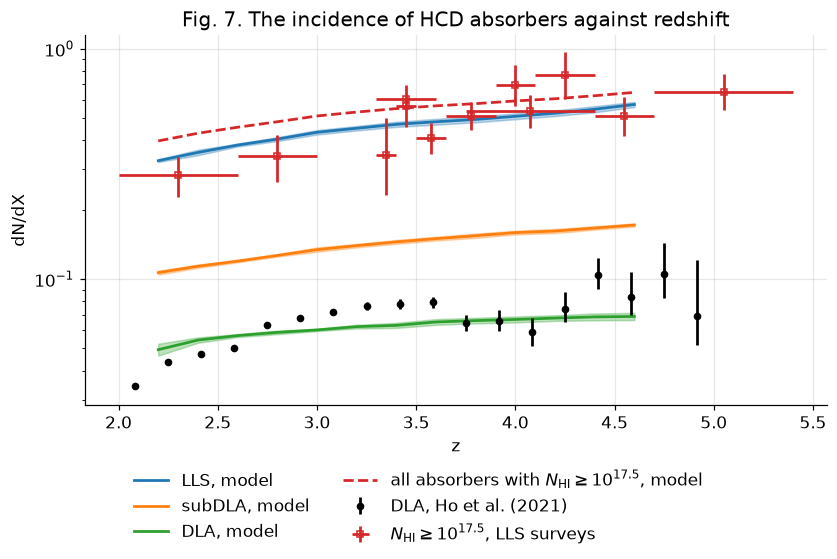

In [14]:
# The DLA incidence of Ho, Bird and Garnett (2021). Rows of the table: redshift, dN/dX, lower and
# upper 68 per cent limits (then the 95 per cent ones, not used here).
table = f"{REPO}/docs/figures/data/ho21/dndx_all.txt"
z_obs, dndx_obs, obs_lower, obs_upper = np.loadtxt(table)[:4]
to_model_x = dx_dz(z_obs, OMEGA_M_HO21) / dx_dz(z_obs, OMEGA_M_MODEL)

fig, ax = plt.subplots(figsize=(7.5, 5))
for c, name in enumerate(hp.HCD_CLASSES):
    ax.plot(redshifts, dndx[:, c], color=f"C{c}", label=f"{name}, model")
    # the held-out range of each prediction, from dndx_lower to dndx_upper
    ax.fill_between(redshifts, dndx_lower[:, c], dndx_upper[:, c], color=f"C{c}", alpha=0.3)
label = r"all absorbers with $N_\mathrm{HI} \geq 10^{17.5}$, model"
ax.plot(redshifts, dndx_all, "--", color="C3", label=label)
errors = [(dndx_obs - obs_lower) * to_model_x, (obs_upper - dndx_obs) * to_model_x]
label = "DLA, Ho et al. (2021)"
ax.errorbar(z_obs, dndx_obs * to_model_x, yerr=errors, fmt="o", color="k", ms=4, label=label)
z_mid, z_half = (z_low + z_high) / 2.0, (z_high - z_low) / 2.0
label = r"$N_\mathrm{HI} \geq 10^{17.5}$, LLS surveys"
style = {"fmt": "s", "color": "C3", "mfc": "none", "ms": 4}
ax.errorbar(z_mid, lls_x, yerr=lls_errors, xerr=z_half, label=label, **style)
ax.set_yscale("log")
ax.set_xlabel("z")
ax.set_ylabel("dN/dX")
ax.set_title("Fig. 7. The incidence of HCD absorbers against redshift")
fig.legend(loc="outside lower center", ncol=2)
plt.show()

**Fig. 7.** The predicted incidence $dN/dX$ of LLSs, subDLAs, DLAs, and all HCD absorbers with $N_\mathrm{HI} \geq 10^{17.5}$ cm$^{-2}$ as a function of redshift, compared with measurements from the literature.

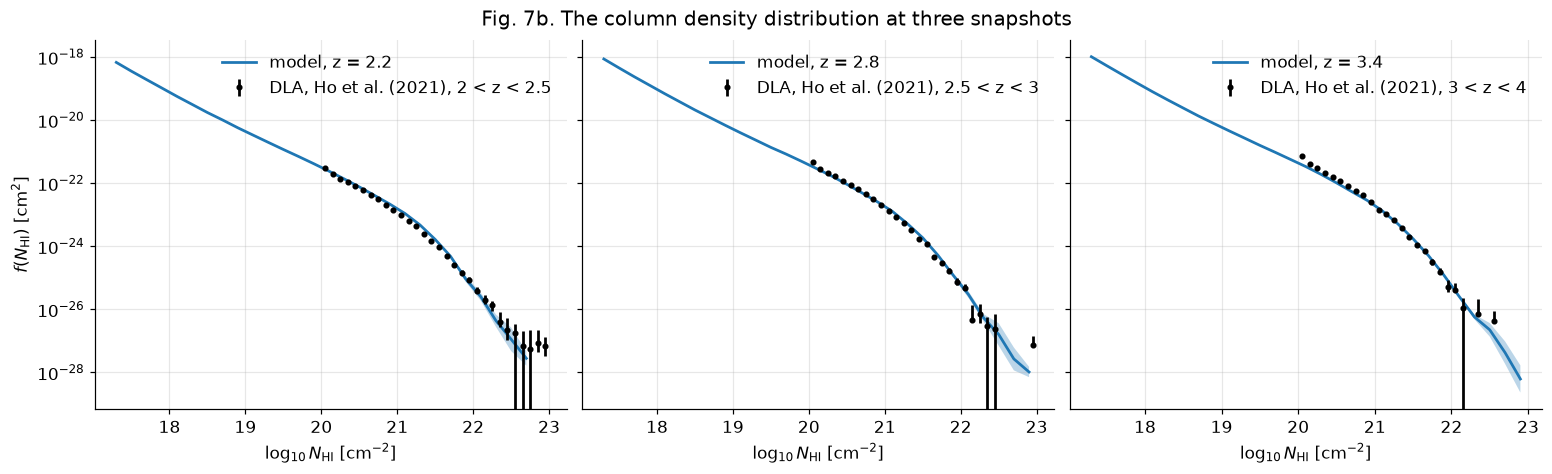

In [15]:
# Three snapshots, each beside the redshift bin of Ho, Bird and Garnett (2021) that holds it.
# Rows of each table: log10 N_HI, f(N_HI), lower and upper 68 per cent limits.
panels = [(2.2, "z225", 2.0, 2.5), (2.8, "z253", 2.5, 3.0), (3.4, "z34", 3.0, 4.0)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (z, name, z_low, z_high) in zip(axes, panels):
    pred_z = emu.predict(PARAMS, z=z, tau0_amp=1.0, dtau0=0.0)
    ax.plot(pred_z.log_nhi, pred_z.cddf, label=f"model, z = {z}")
    ax.fill_between(pred_z.log_nhi, pred_z.cddf_lower, pred_z.cddf_upper, alpha=0.3)
    table = f"{REPO}/docs/figures/data/ho21/cddf_{name}.txt"
    log_n, f, lower, upper = np.loadtxt(table)[:4]
    # the measurement's absorption distance over its redshift bin, put on the model's cosmology
    z_bin = np.linspace(z_low, z_high, 201)
    to_model_x = np.mean(dx_dz(z_bin, OMEGA_M_HO21)) / np.mean(dx_dz(z_bin, OMEGA_M_MODEL))
    seen = f > 0  # a bin with f = 0 holds no detection
    points = f[seen] * to_model_x
    errors = [(f - lower)[seen] * to_model_x, (upper - f)[seen] * to_model_x]
    label = f"DLA, Ho et al. (2021), {z_low:g} < z < {z_high:g}"
    ax.errorbar(log_n[seen], points, yerr=errors, fmt="o", color="k", ms=3, label=label)
    ax.set_yscale("log")
    ax.set_xlabel(r"$\log_{10} N_\mathrm{HI}$ [cm$^{-2}$]")
    ax.legend(loc="upper right")
axes[0].set_ylabel(r"$f(N_\mathrm{HI})$ [cm$^{2}$]")
fig.suptitle("Fig. 7b. The column density distribution at three snapshots")
plt.show()

**Fig. 7b.** The predicted column density distribution function (CDDF) at three different redshifts, compared with measurements from the literature.

### How does the abundance of HCD absorbers depend on cosmology and astrophysics?

Now let's explore how the abundance of HCD absorbers depends on the input parameters of the emulator. We will vary one parameter, the amplitude of the primordial power spectrum $A_p$, across its training range and see how the predicted incidence $dN/dX$ of each HCD population changes with redshift, while keeping all other parameters fixed.

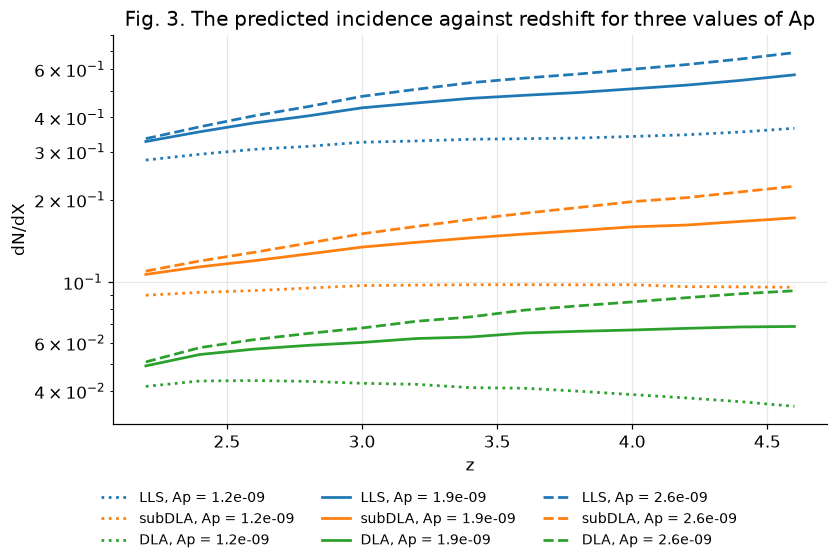

In [16]:
# One parameter is varied: the amplitude A_p of the primordial power spectrum, at the two ends and
# the middle of its trained range. predict_many returns every redshift of one parameter point.
low, high = hp.PARAM_LIMITS[hp.PARAM_NAMES.index("Ap")]
fig, ax = plt.subplots(figsize=(7.5, 5))
for value, style in zip((low, PARAMS["Ap"], high), (":", "-", "--")):
    many = emu.predict_many({**PARAMS, "Ap": value}, z=redshifts, tau0_amp=1.0, dtau0=0.0)
    for c, name in enumerate(hp.HCD_CLASSES):
        ax.plot(redshifts, many.dndx[:, c], style, color=f"C{c}", label=f"{name}, Ap = {value:.1e}")
ax.set_yscale("log")
ax.set_xlabel("z")
ax.set_ylabel("dN/dX")
ax.set_title("Fig. 3. The predicted incidence against redshift for three values of Ap")
fig.legend(loc="outside lower center", ncol=3, fontsize=9)
plt.show()

### Two ways to change the contribution of HCD absorbers to the P1D

We have now seen two different ways to change the contribution of HCD absorbers to the total P1D:

1. **Changing the HCD amplitude $A_c$:** We change the fraction of sightlines belonging to a given HCD population while keeping the P1D of each population fixed. This is how we usually treat HCD contamination with nuisance parameters in cosmological inference.

2. **Changing the cosmological and astrophysical parameters:** We change the underlying physical model, which changes both the abundance of HCD absorbers and the P1D of each population of sightlines.

Let's compare these two approaches using LLSs as an example.

In [17]:
LLS = hp.HCD_CLASSES.index("LLS")  # the place of the LLS class in pred.dndx and pred.w_c
# (A) The LLS amplitude doubled by hand. No new prediction is made: the incidence does not change.
doubled = pred.w_c.copy()
doubled[LLS] *= 2.0
# (B) One parameter moved. This is a new prediction, with its own incidence and fractions.
pred_b = emu.predict({**PARAMS, "Ap": 2.6e-9}, z=3.0, tau0_amp=1.0, dtau0=0.0)

print("                      dN/dX of LLS   LLS amplitude in the mixture")
print(f"the prediction above  {pred.dndx[LLS]:.4f}         {pred.w_c[LLS]:.4f}")
print(f"(A) amplitude x 2     {pred.dndx[LLS]:.4f}         {doubled[LLS]:.4f}")
print(f"(B) Ap = 2.6e-9       {pred_b.dndx[LLS]:.4f}         {pred_b.w_c[LLS]:.4f}")

                      dN/dX of LLS   LLS amplitude in the mixture
the prediction above  0.4337         0.2126
(A) amplitude x 2     0.4337         0.4252
(B) Ap = 2.6e-9       0.4777         0.2276


### How far we can trust it?

To estimate the accuracy of the emulator, we compare its predictions with simulations that were left out of the training set. For each population of sightlines and for the combined P1D, we compute the root mean square of the log-ratio between the predicted and simulated P1D:

$$
e(k) = \sqrt{\left\langle \left[\ln\frac{P_\mathrm{pred}(k)}{P_\mathrm{sim}(k)}\right]^2 \right\rangle}.
$$

We can use $P(k)\exp[\pm e(k)]$ to visualize the typical prediction error at each scale. Note that this is an empirical estimate of the emulator error rather than a calibrated predictive uncertainty.

Our multi-fidelity emulator is validated over the redshift range $2.2 \leq z \leq 4.6$. The emulator returns a warning flag for predictions above this range and does not support predictions below $z = 2.2$ or interpolation between simulation snapshots.

In [18]:
# e is the rms of ln(prediction / truth) over simulations the model was made without,
# one value per wavenumber. As a range on the spectrum it is times exp(-e) to times exp(+e).
e = pred.P_mix_validation_rms_log
for label, value in (("median", np.nanmedian(e)), ("largest", np.nanmax(e))):
    low, high = np.exp(-value), np.exp(value)
    print(f"{label} e = {value:.3f}: the mixture times {low:.3f} to times {high:.3f}")

median e = 0.009: the mixture times 0.991 to times 1.009
largest e = 0.036: the mixture times 0.964 to times 1.037


In [19]:
# Above z = 4.6 a prediction is returned with flags (the first is mf_z_above_validated);
# between snapshot redshifts it is refused.
high = emu.predict(PARAMS, z=4.8, tau0_amp=1.0, dtau0=0.0)
set_at_3 = {name for name, value in pred.flags.items() if value is True}
set_at_48 = {name for name, value in high.flags.items() if value is True}
print("flags set at z = 4.8 and not at z = 3:", sorted(set_at_48 - set_at_3))
try:
    emu.predict(PARAMS, z=3.1, tau0_amp=1.0, dtau0=0.0)
except hp.PredictorInputError as error:
    print("z = 3.1 is refused:", error)

flags set at z = 4.8 and not at z = 3: ['mf_z_above_validated', 'w_c_xbar_extrapolated', 'z_downweighted']
z = 3.1 is refused: z = 3.1 is not a PRIYA snapshot redshift (2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.2, 3.4, 3.6, 3.8, 4.0, 4.2, 4.4, 4.6, 4.8, 5.0, 5.2, 5.4) (tolerance 1e-09)


### Comparison with the HCD model of Rogers et al. (2018)

Rogers et al. (2018) developed a model for HCD contamination in the Lyman-alpha forest P1D. The idea is to use hydrodynamical simulations to model the ratio of the P1D of sightlines containing different populations of HCD absorbers to that of clean sightlines, as a function of $k$ and $z$.

Our emulator builds on this idea with two main differences:

- We model how the P1D of each population of sightlines depends on cosmological and astrophysical parameters, as well as the mean flux.
- We also predict how the abundance of each HCD population depends on cosmology and astrophysics.

Let's compare the range of P1D ratios across the PRIYA training simulations with the model of Rogers et al. (2018). For this comparison, we use the simulation spectra with the absorption removed by the PRIYA filter restored.

For more details on the comparison, see [the documentation](../../docs/rogers_comparison.md).

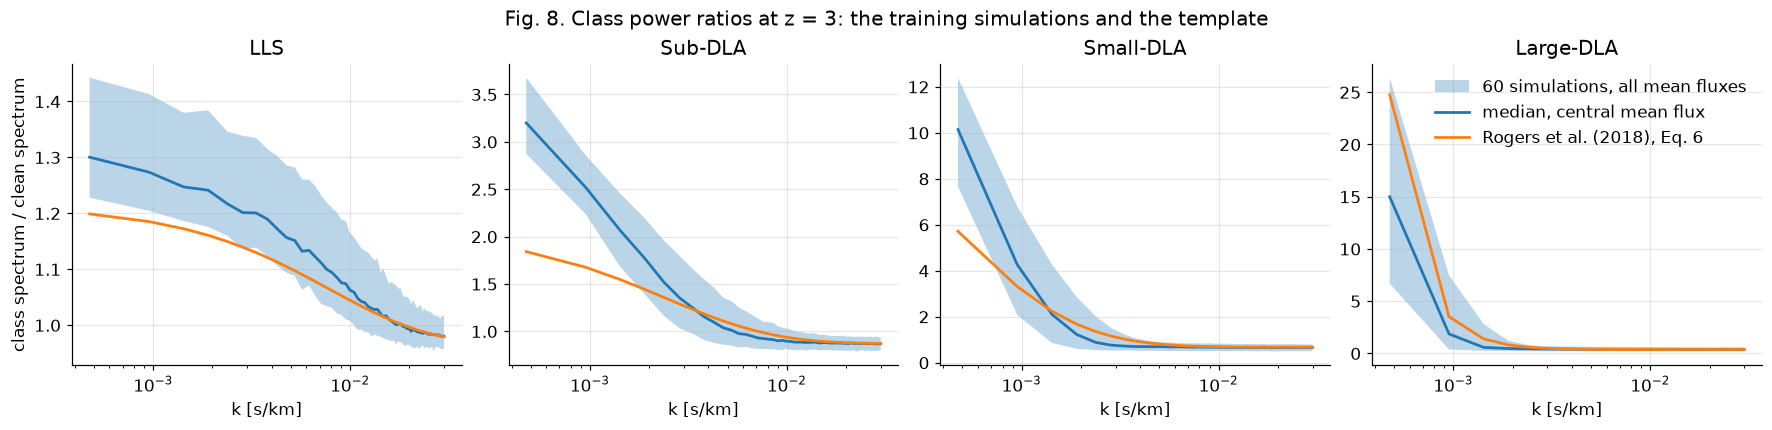

In [20]:
# The class power ratio of the 60 training simulations at z = 3, with the filtered absorption
# restored (a table of the repository), beside Eq. 6 of Rogers et al. (2018) from the package.
table = f"{REPO}/docs/figures/data/class_ratio_ranges_z3p0_lf60.csv"
sims = np.genfromtxt(table, delimiter=",", names=True, skip_header=8)
k = sims["k_s_per_km"]
template = hcd_template.class_ratio(k, 3.0)  # a dictionary, one curve per class of Rogers et al.

# the table's column name of each class, and the name Rogers et al. give it
classes = {"LLS": "LLS", "subDLA": "Sub-DLA", "smallDLA": "Small-DLA", "largeDLA": "Large-DLA"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (column, rogers_name) in zip(axes, classes.items()):
    low = sims[f"R_{column}_sims60_allrungs_min"]
    high = sims[f"R_{column}_sims60_allrungs_max"]
    ax.fill_between(k, low, high, alpha=0.3, label="60 simulations, all mean fluxes")
    ax.plot(k, sims[f"R_{column}_sims60_rung1_p50"], label="median, central mean flux")
    ax.plot(k, template[rogers_name], color="C1", label="Rogers et al. (2018), Eq. 6")
    ax.set_xscale("log")
    ax.set_xlabel("k [s/km]")
    ax.set_title(rogers_name)
axes[0].set_ylabel("class spectrum / clean spectrum")
axes[3].legend()
fig.suptitle("Fig. 8. Class power ratios at z = 3: the training simulations and the template")
plt.show()

**Fig. 8.** Comparison of the P1D ratios from the PRIYA simulations with the HCD model of Rogers et al. (2018). For this comparison, we restore the absorption removed by the PRIYA filter.

## Part III. Cosmological inference with the HCD emulator

Now that we have explored how HCD absorbers affect the P1D, let's see how we can incorporate this information into cosmological inference. We will go through an example with a mock data set and examine the results of a previously run mock-recovery analysis.

### The Gaussian likelihood

Given a measured P1D data vector $d$ and its covariance matrix $C$, we can construct a Gaussian likelihood:

$$
\ln \mathcal{L}(\theta) =
-\frac{1}{2}[d - m(\theta)]^T C^{-1}[d - m(\theta)]
-\frac{1}{2}\ln\det C
-\frac{N}{2}\ln 2\pi,
$$

where $m(\theta)$ is the model prediction at a given set of parameters $\theta$, and $N$ is the number of data points.

To construct the model vector $m(\theta)$, we need to:

1. Predict the P1D of each population of sightlines at the redshifts of the data.
2. Combine the four populations of sightlines with their corresponding HCD amplitudes.
3. Interpolate the predicted P1D onto the $k$ bins of the data.
4. Apply any additional multiplicative corrections specific to the data set.

These steps are implemented in `hcd_analysis.likelihood.GaussianP1DLikelihood`. For more details on the likelihood and its assumptions, see [the likelihood documentation](../../docs/likelihood.md).

Let's first evaluate the likelihood at the input parameters of the mock data set and explore how it changes with the HCD amplitudes.

In [21]:
# The example data set holds a mock, a held-out model and a stored reference. The example script
# of the clone lists each file with its sha256, and every loader checks the file it reads.
sys.path.insert(0, f"{REPO}/examples")
import mock_recovery as example

root = "hcd_priya_example_download"
path = {name: f"{root}/{relative}" for name, (relative, _) in example.DOWNLOAD.items()}
sha256 = {name: digest for name, (_, digest) in example.DOWNLOAD.items()}

data = likelihood.read_p1d_data(path["mock"], expected_sha256=sha256["mock"])
reference = likelihood.read_reference(path["reference"], expected_sha256=sha256["reference"])
z_low, z_high = min(data.z), max(data.z)
print(f"the mock: {data.n} bins at {len(data.z)} redshifts, z = {z_low:.1f} to {z_high:.1f}")

the mock: 121 bins at 11 redshifts, z = 2.2 to 4.2


For the mock-recovery analysis, we use the P1D from one of the PRIYA simulations as our mock data. To test whether we can recover the input parameters of this simulation, we use an emulator trained on the remaining simulations.

We will therefore load this held-out emulator instead of the published emulator we used in Part II.

In [22]:
# The held-out model: trained without the simulation the mock comes from. It is a research bundle,
# so it is loaded with its purpose stated, together with its multi-fidelity and incidence records.
emu_heldout = hp.load_research_bundle(
    path["model"],
    sha256["model"],
    purpose=example.DOWNLOAD_PURPOSE,
    mf_dir=path["mf_record"],
    mf_record_sha256=sha256["mf_record"],
    incidence_dir=path["incidence_record"],
    incidence_record_sha256=sha256["incidence_record"],
)
print("purpose of this model:", example.DOWNLOAD_PURPOSE)

purpose of this model: the mock-recovery example: a held-out recovery of the mock of the example download


In [23]:
like = likelihood.GaussianP1DLikelihood(emu_heldout, data, gaussian_terms=example.GAUSSIAN_TERMS)
truth = dict(data.truth)  # the parameters the mock was made at
# The held-out model warns about its dN/dX and CDDF. A warning shown by Jupyter would also print
# where the package is installed on this machine, so it is caught and its message printed instead.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    chi2_truth = like.chi2(truth)
    loglike_truth = like.loglike(truth)
for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")
print(f"chi-square at the truth: {chi2_truth:.4f} for {data.n} bins (0 is an exact reproduction)")
print(f"log-likelihood at the truth: {loglike_truth:.2f}")

chi-square at the truth: 1.5008 for 121 bins (0 is an exact reproduction)
log-likelihood at the truth: -93.16


We do not have estimates of the prediction error for the incidence $dN/dX$ and the CDDF in this held-out emulator. This is not an issue for our mock-recovery analysis, since we only use the P1D in the likelihood.

In [24]:
print("three evaluations of the public likelihood at the mock's truth;")
print("nothing is fitted and these are not constraints")
for r_lls in (0.0, 1.0, 2.0):
    # hcd_relative_to_priya sets the amplitude of a class relative to the model's own fraction
    relative = {"LLS": r_lls, "subDLA": 1.0, "DLA": 1.0}
    scaled = likelihood.GaussianP1DLikelihood(
        emu_heldout, data, gaussian_terms=example.GAUSSIAN_TERMS, hcd_relative_to_priya=relative
    )
    chi2 = scaled.chi2(truth)
    print(f"LLS amplitude at {r_lls:g} times the model's own fraction: chi-square = {chi2:.4f}")

three evaluations of the public likelihood at the mock's truth;
nothing is fitted and these are not constraints
LLS amplitude at 0 times the model's own fraction: chi-square = 2.9302
LLS amplitude at 1 times the model's own fraction: chi-square = 1.5008
LLS amplitude at 2 times the model's own fraction: chi-square = 4.8629


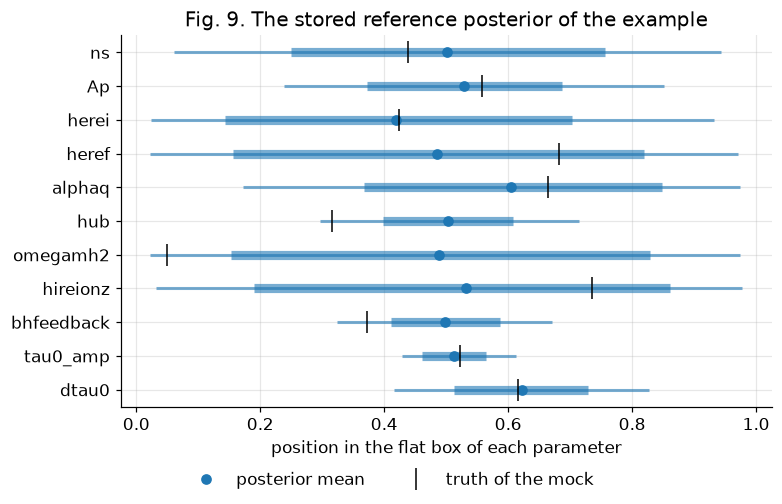

In [25]:
# The stored reference: for each of the eleven parameters the posterior mean and the central 68
# and 95 per cent intervals, with the truth of the mock, each on the scale of its flat box.
names = reference.param_names
low = np.array([example.BOXES[name][0] for name in names])
width = np.array([example.BOXES[name][1] for name in names]) - low
rows = np.arange(len(names))

fig, ax = plt.subplots(figsize=(7, 4.5))
for interval, thickness in ((reference.interval95, 2), (reference.interval68, 6)):
    scaled = (interval - low[:, None]) / width[:, None]
    ax.hlines(rows, scaled[:, 0], scaled[:, 1], color="C0", lw=thickness, alpha=0.6)
ax.plot((reference.mean - low) / width, rows, "o", color="C0", label="posterior mean")
ax.plot((reference.truth - low) / width, rows, "|", color="k", ms=14, label="truth of the mock")
ax.set_yticks(rows, names)
ax.invert_yaxis()
ax.set_xlabel("position in the flat box of each parameter")
ax.set_title("Fig. 9. The stored reference posterior of the example")
fig.legend(loc="outside lower center", ncol=2)
plt.show()

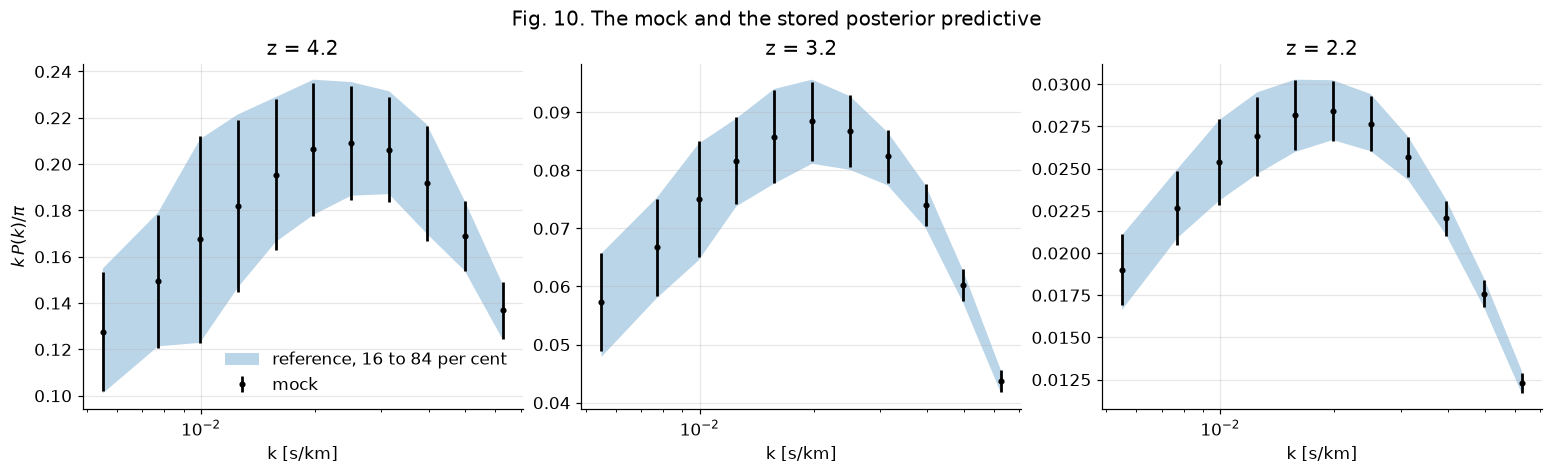

In [26]:
# The mock beside the stored posterior predictive of the reference, at three of eleven redshifts.
band_low, band_high = reference.band(16.0, 84.0)
sigma = np.sqrt(np.diag(data.cov))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, i in zip(axes, (0, 5, 10)):
    bins = data.slices()[i]
    k = np.asarray(data.k[i])
    scale = k / np.pi  # the dimensionless k P(k) / pi
    low, high = scale * band_low[bins], scale * band_high[bins]
    ax.fill_between(k, low, high, alpha=0.3, label="reference, 16 to 84 per cent")
    errors = scale * sigma[bins]
    ax.errorbar(k, scale * data.p1d[bins], yerr=errors, fmt=".", color="k", label="mock")
    ax.set_xscale("log")
    ax.tick_params(axis="x", which="minor", labelbottom=False)
    ax.set_xlabel("k [s/km]")
    ax.set_title(f"z = {data.z[i]:.1f}")
axes[0].set_ylabel(r"$k\,P(k)/\pi$")
axes[0].legend()
fig.suptitle("Fig. 10. The mock and the stored posterior predictive")
plt.show()

**Fig. 9.** Posterior constraints on the eleven parameters from the mock-recovery analysis. We show the posterior mean and the 68% and 95% credible intervals, together with the input parameters of the mock simulation.

**Fig. 10.** The posterior predictive P1D compared with the mock data at three different redshifts. We show the central 68% interval of the posterior predictions.

Both figures are generated from the stored results of the mock-recovery analysis, without rerunning the MCMC chains in this tutorial.

### Reproducing the results

The table below summarizes what you can reproduce with this tutorial and the public release of `hcd_priya`.

| Result | How to reproduce it |
|---|---|
| Emulator predictions and figures in Part II | Run this notebook. |
| Likelihood and $\chi^2$ evaluations in Part III | Run this notebook with the example data set. |
| Mock-recovery results (Figs. 9 and 10) | Run this notebook to generate the figures from the stored posterior summaries. |
| Full mock-recovery analysis | Run `python examples/mock_recovery.py --download DIR --full` with Cobaya to generate your own MCMC chains. |
| Cosmological constraints and comparison with the Gaussian-process emulator (Fig. 3 of the paper) | The original MCMC chains are not included in the public release. |

## Limitations and further reading

Before using `hcd_priya` for your own analysis, there are a few things to keep in mind:

- The likelihood currently uses only the data covariance matrix. We do not include the emulator prediction error in the likelihood.
- The predicted P1D follows the PRIYA filtering convention. Depending on how HCD absorbers are treated in your data, additional corrections may be needed.
- In this tutorial, we have illustrated how to construct and evaluate the likelihood. To obtain your own posterior constraints, you will need to run the MCMC analysis.

If you would like to explore further:

- [Likelihood documentation](../../docs/likelihood.md): how to construct the likelihood for your own data set.
- [Mock-recovery example](../../examples/mock_recovery.py): how to run an MCMC analysis with the emulator.
- [Model predictions and comparisons](../../docs/model_figures.md): more comparisons between the emulator predictions and measurements from the literature.